## Kattegat Fishing Harbours, Vessel Size, and Official-Route Avoidance (Flag 8)

### Dataset Overview
This derived case uses AIS-like position, time, speed, and course fields consistent with the Section 9.1 AIS description, together with vessel attributes, harbour locations, and report-line-style A/E route references. Section 9.4 identifies Anholt, Bønnerup, and Grenaa as the main fishing harbours, notes the predominance of smaller vessels, and describes fishing sailing patterns as more random than larger-vessel traffic because fishing vessels do not follow official routes. The concrete trajectories and small-harbour calls are for this case.

The notebook exposes a primary table and a supporting table (`vessel_attributes.csv`).

Goal: To detect and investigate movement patterns of fishing vessels with given trajectories of fishing vessels and other type vessels in this area.

Role: Maritime traffic analyst


Category: Kattegat fishing activity, vessel size, and route adherence

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessel_attributes.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which harbours anchor the fishing-vessel activity, and how concentrated are the observed fishing-trip endpoints among them?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

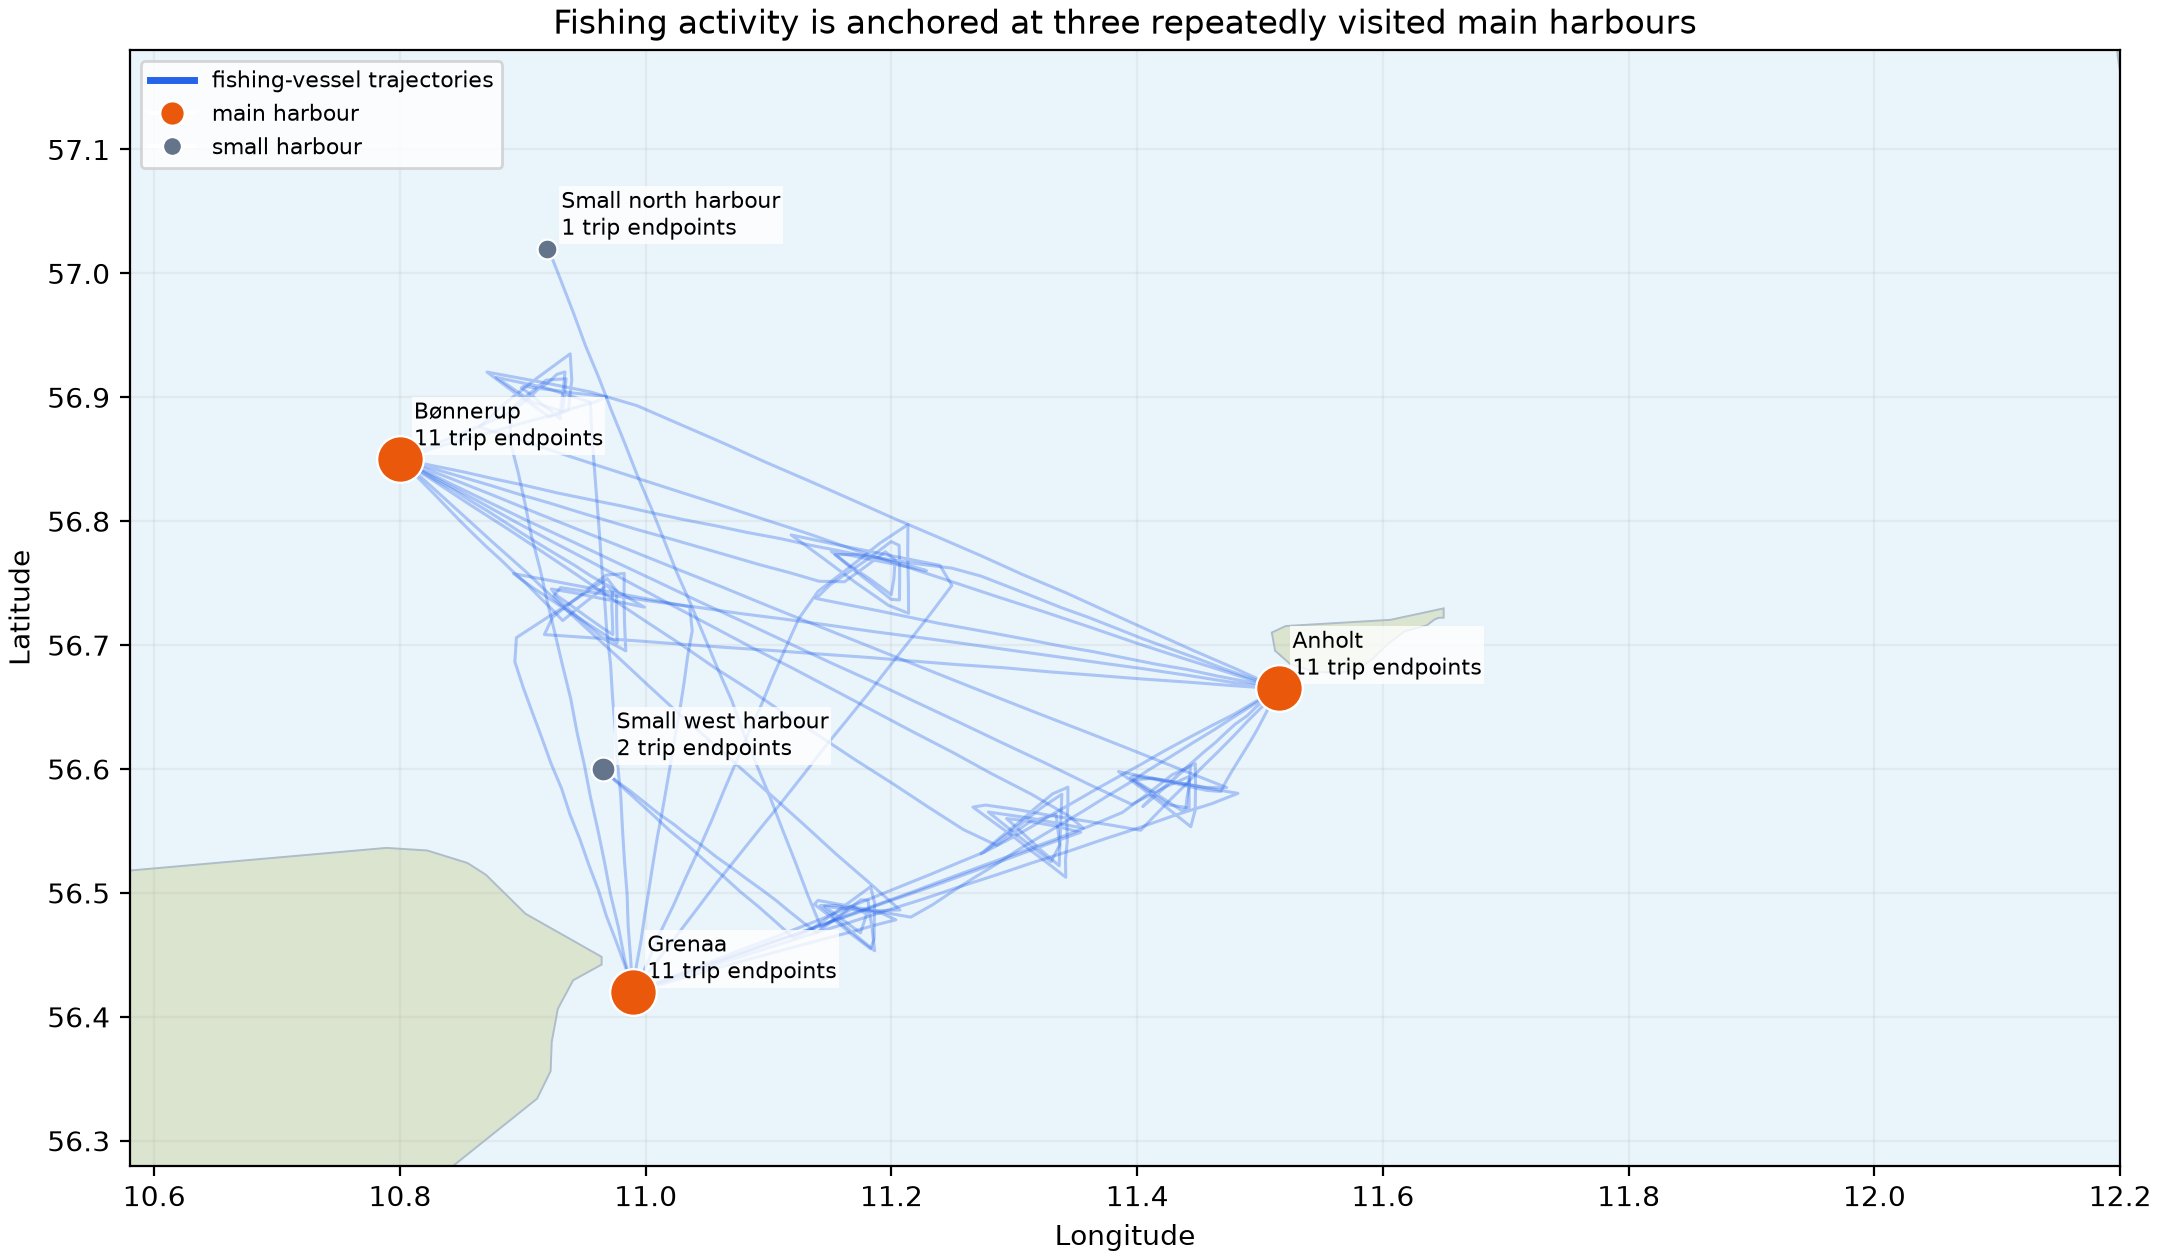

In [ ]:
import pandas as pd
from pathlib import Path
points = pd.read_csv(dataset_path)
ships = pd.read_csv(user_dataset_path)
harbours = pd.read_csv(Path('harbours.csv'))
fish_ids = ships.loc[ships['ship_type'].eq('Fishing'), 'vessel_id']
print(points[points['vessel_id'].isin(fish_ids)].groupby('trajectory_id').size())
# Assign trip endpoints to their nearest supplied harbour and count visits.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/fishing_harbour_activity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "harbour_activity_structure",
  "insight": "Three main harbours structure fishing activity in the selected sea area: Anholt, Bønnerup, and Grenaa. They account for 33 of 36 observed fishing-trip endpoints, whereas the supplied small harbours receive only occasional calls.",
  "insight_value": {
    "main_harbours": [
      "Anholt",
      "Bønnerup",
      "Grenaa"
    ],
    "main_harbour_endpoints": 33,
    "all_fishing_trip_endpoints": 36
  },
  "plot": {
    "plot_type": "geographic_harbour_activity_map",
    "title": "Fishing Activity by Harbour",
    "file": "visualizations/fishing_harbour_activity.png",
    "description": "Harbour-circle size encodes trajectory endpoints; the three repeatedly used ports contrast with occasional calls at the small harbours."
  },
  "question": "Which harbours anchor the fishing-vessel activity, and how concentrated are the observed fishing-trip endpoints among them?",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\nships = pd.read_csv(user_dataset_path)\nharbours = pd.read_csv(Path('harbours.csv'))\nfish_ids = ships.loc[ships['ship_type'].eq('Fishing'), 'vessel_id']\nprint(points[points['vessel_id'].isin(fish_ids)].groupby('trajectory_id').size())\n# Assign trip endpoints to their nearest supplied harbour and count visits.",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "harbour_location",
    "vessel_id"
  ]
}

### **Question 2**: How are fishing-vessel dimensions distributed, and how many fishing vessels are shorter than 15 m?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

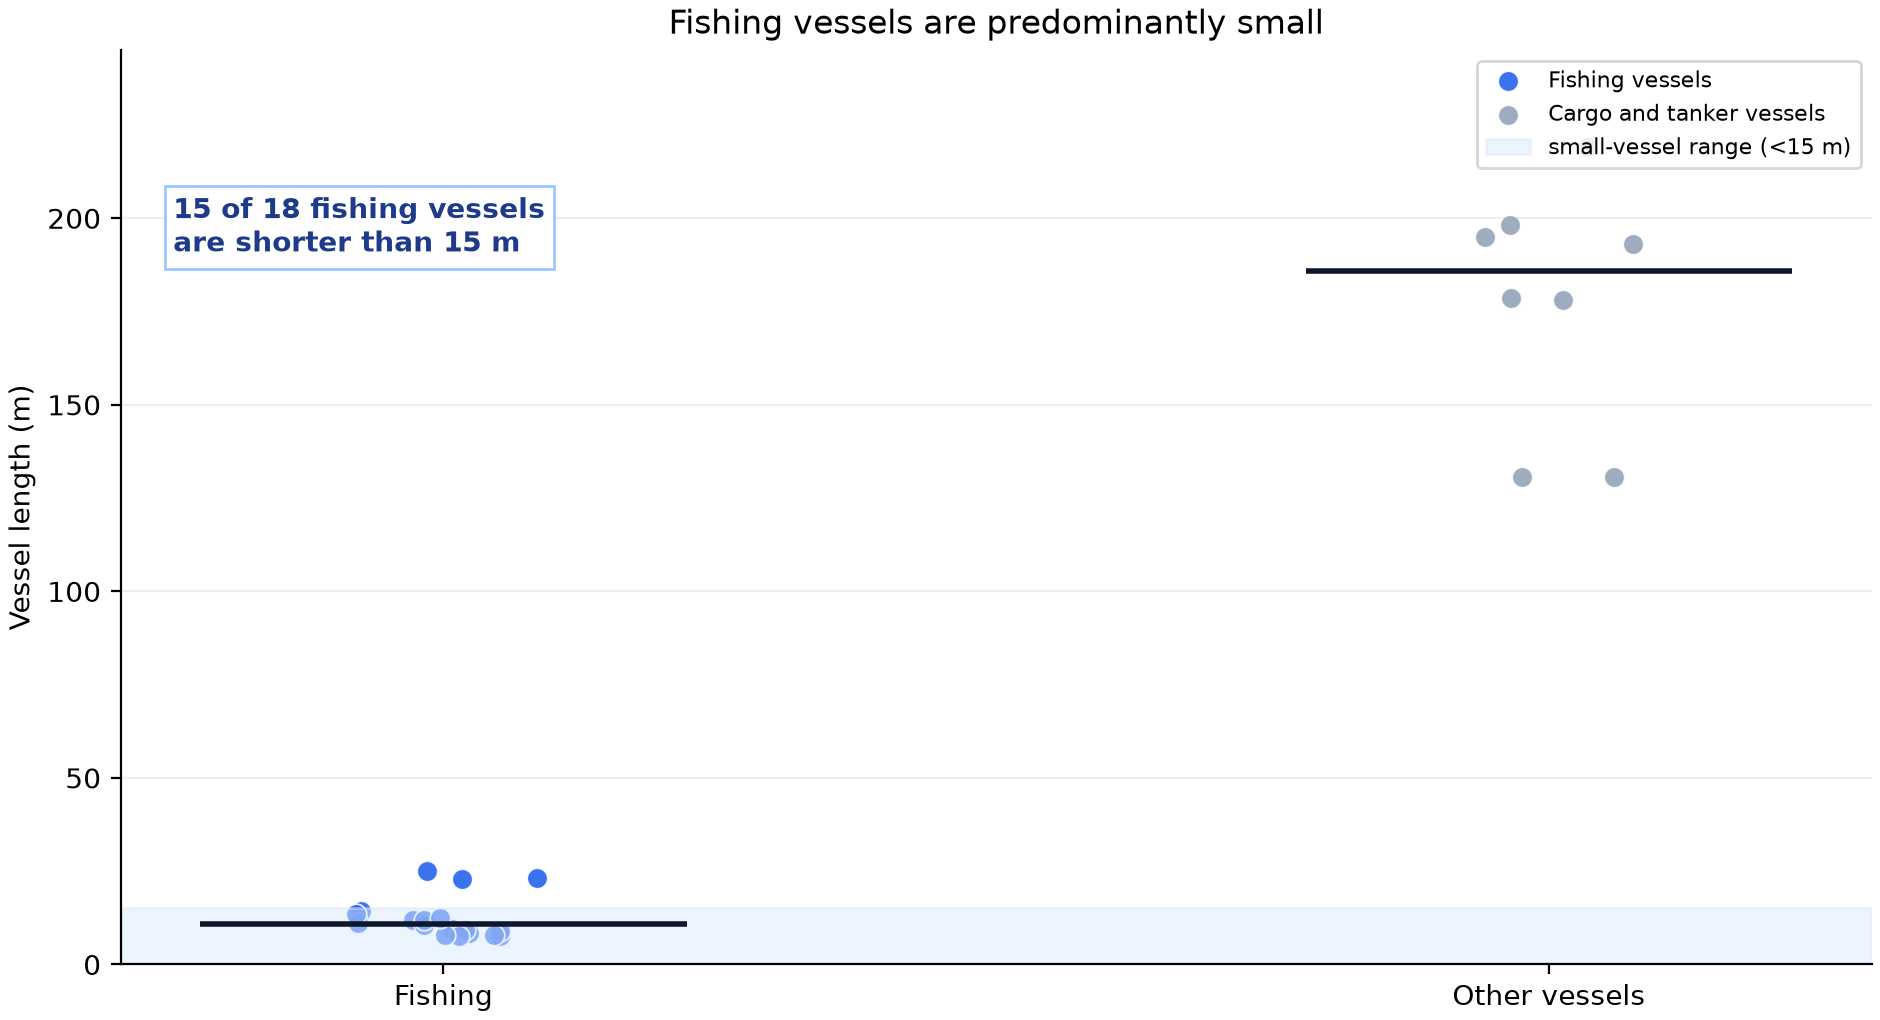

In [ ]:
import pandas as pd
ships = pd.read_csv(user_dataset_path)
fish = ships[ships['ship_type'].eq('Fishing')]
print(fish['length_m'].describe())
print((fish['length_m'] < 15).value_counts())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/fishing_vessel_size_distribution.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_dimension_distribution",
  "insight": "Fishing vessels are predominantly small: 15 of 18 fishing vessels are shorter than 15 m, while only three are larger fishing vessels.",
  "insight_value": {
    "fishing_vessels_under_15m": 15,
    "fishing_vessels_15m_or_longer": 3,
    "total_fishing_vessels": 18
  },
  "plot": {
    "plot_type": "jittered_length_distribution",
    "title": "Fishing-Vessel Size Distribution",
    "file": "visualizations/fishing_vessel_size_distribution.png",
    "description": "Individual vessel lengths reveal a dense small-vessel group and only a few larger fishing vessels."
  },
  "question": "How are fishing-vessel dimensions distributed, and how many fishing vessels are shorter than 15 m?",
  "code": "import pandas as pd\nships = pd.read_csv(user_dataset_path)\nfish = ships[ships['ship_type'].eq('Fishing')]\nprint(fish['length_m'].describe())\nprint((fish['length_m'] < 15).value_counts())",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "vessel_length",
    "vessel_id"
  ]
}

### **Question 3**: How does fishing-vessel route adherence differ from that of the larger vessels when both are compared with the two supplied official transit corridors?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

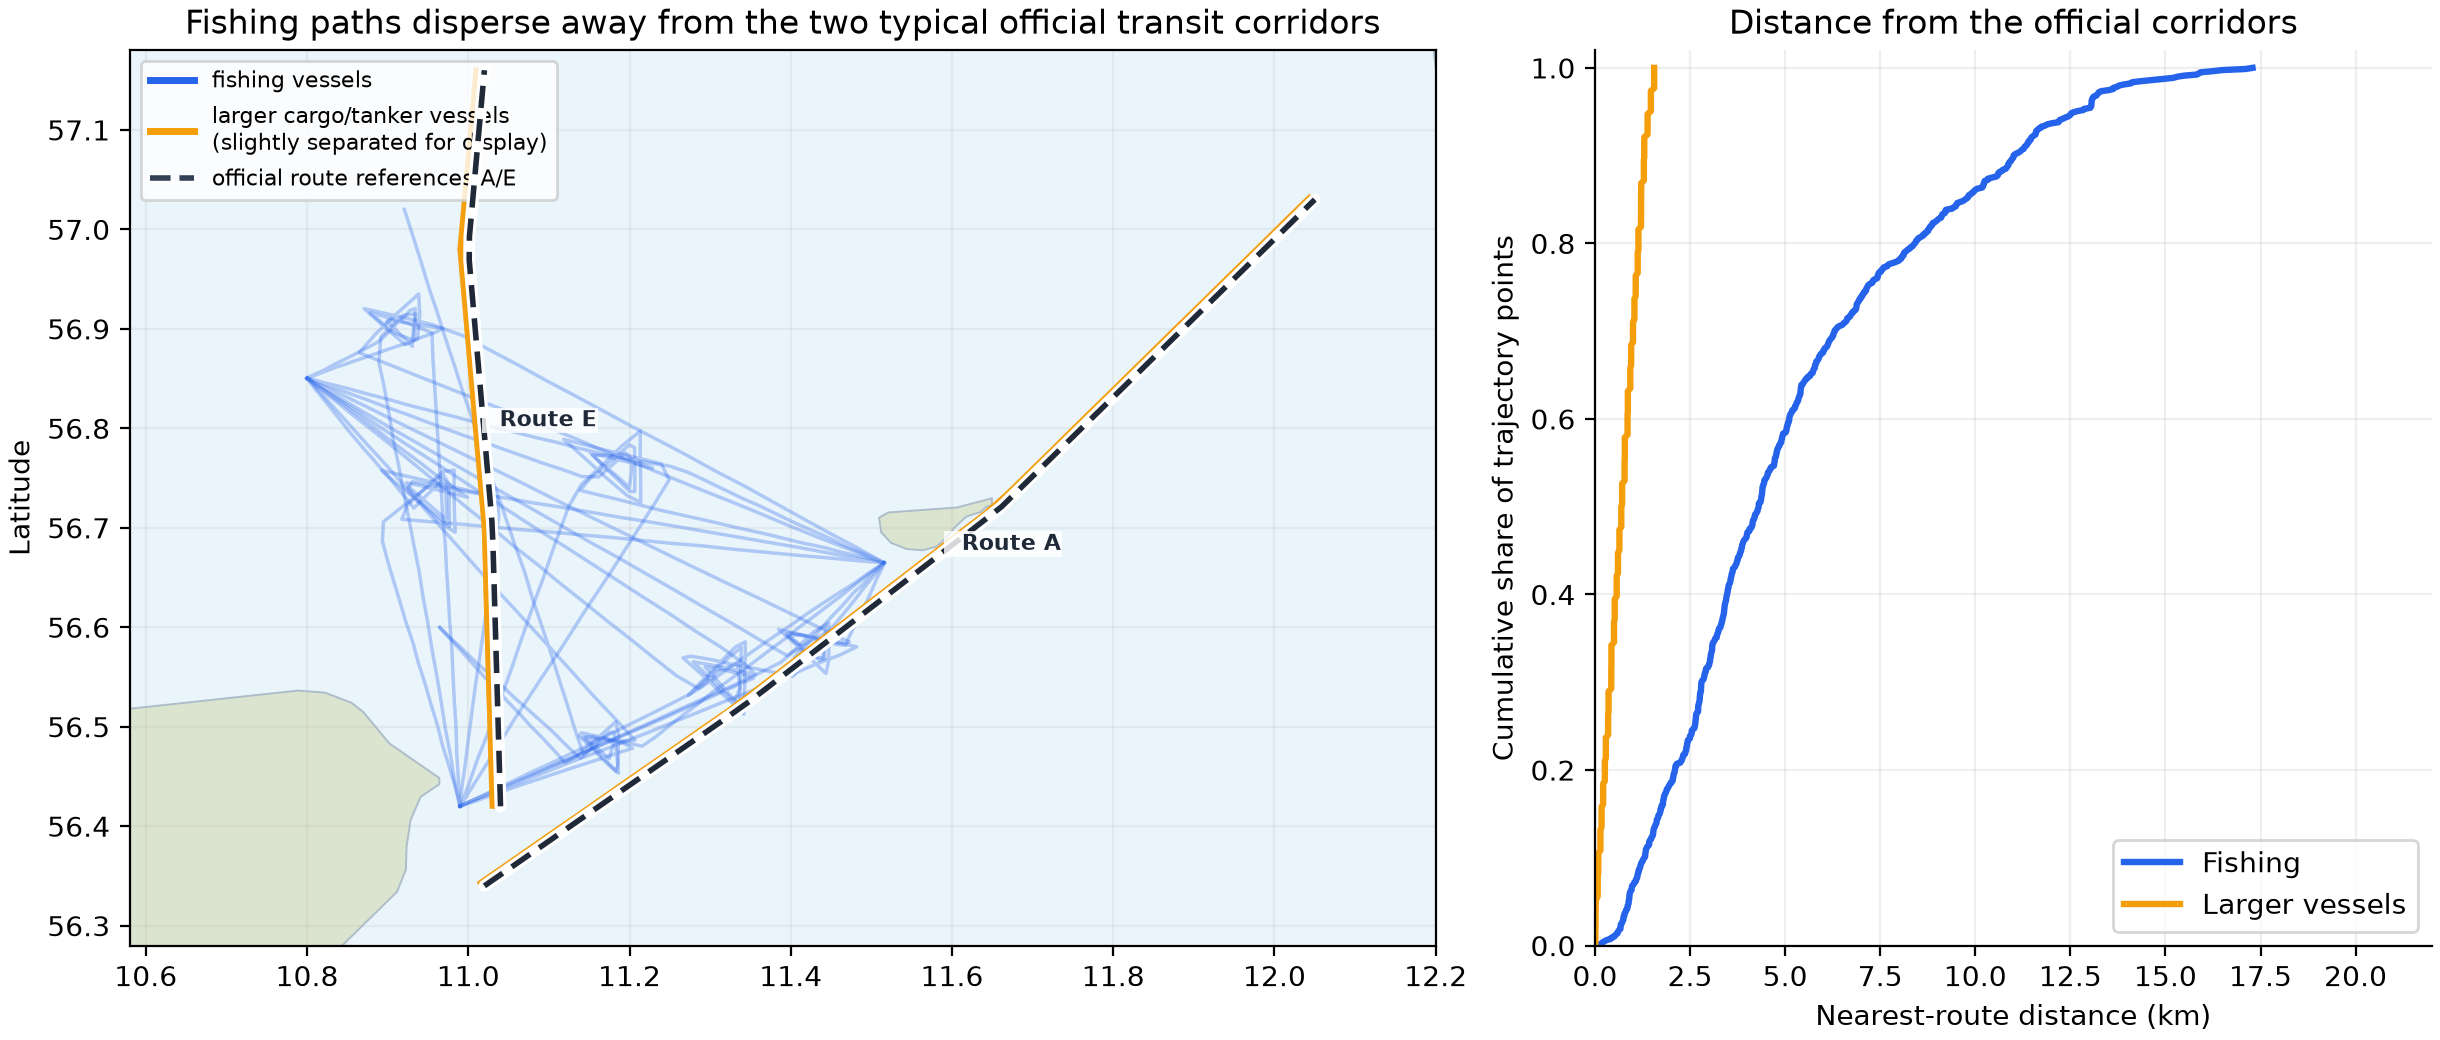

In [ ]:
import pandas as pd
from pathlib import Path
points = pd.read_csv(dataset_path)
ships = pd.read_csv(user_dataset_path)
references = pd.read_csv(Path('official_transit_routes.csv'))
print(references.groupby(['route_name','direction']).size())
# Compute each point's nearest distance to the A/E references, then compare Fishing with Cargo/Tanker.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/fishing_vs_official_routes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_adherence_comparison",
  "insight": "Fishing-vessel trajectories are far more spatially dispersed than the larger cargo and tanker trajectories. The larger vessels closely follow the supplied A and E official transit references, whereas fishing vessels repeatedly move between nearshore grounds and harbours and do not consistently align with either corridor.",
  "insight_value": {
    "reference_corridors": [
      "A",
      "E"
    ],
    "comparison": "fishing trajectories have a much broader nearest-route-distance distribution"
  },
  "plot": {
    "plot_type": "map_and_ecdf_comparison",
    "title": "Fishing Movement versus Official Transit Corridors",
    "file": "visualizations/fishing_vs_official_routes.png",
    "description": "The map compares trajectory geometry with two supplied official-route references; the ECDF summarizes nearest-corridor distances."
  },
  "question": "How does fishing-vessel route adherence differ from that of the larger vessels when both are compared with the two supplied official transit corridors?",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\nships = pd.read_csv(user_dataset_path)\nreferences = pd.read_csv(Path('official_transit_routes.csv'))\nprint(references.groupby(['route_name','direction']).size())\n# Compute each point's nearest distance to the A/E references, then compare Fishing with Cargo/Tanker.",
  "insight_type": "group_comparison",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "vessel_length",
    "gps_position",
    "official_route_reference",
    "harbour_location",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 8)

Fishing activity in the selected Kattegat area is concentrated around Anholt, Bønnerup, and Grenaa, and most fishing vessels are small. Unlike the provided cargo and tanker movements, fishing trajectories disperse among nearshore grounds and harbour calls rather than closely tracking the two official transit corridors.